# 06 · 断点续传与 XXL-JOB


## 资料来源与当天目标

本篇对应网盘 14 天规划中的 **day06 断点续传 xxl-job**。第 05 天完成图片上传和基础设施接入；第 06 天把上传对象扩展到大视频，实现分块检查、分块上传、按序合并和完整性校验，同时接入分布式任务调度，为下一天的视频转码准备执行环境。

| 资料 | 本篇使用范围 |
|---|---|
| 《第3章媒资管理模块v3.1.docx》 | 第 5 节上传视频，以及第 7.2 节分布式任务处理；复用第 05 天已下载的同章完整讲义，包含正文、示例代码与原图 |
| 网盘 day06 / 资料 | 核对到同名讲义、`RestResponse.java`、`xxl-job-2.3.1.zip`、工具类、前端文件目录 |
| day06 / 资料 / `RestResponse.java` | 从网盘代码预览读取完整类，核对 `code`、`msg`、`result` 与 `success/validfail/isSuccessful` 方法 |
| 第 05 天的 Nacos 配置导出 | 核对 `media-service-dev.yaml` 中 MinIO、XXL-JOB 配置和 `media-api-dev.yaml` 的端口、上下文路径 |
| XXL-JOB 官方 2.3.1 源码 | 核对执行器配置类、BEAN 任务写法、分片参数、执行日志和 Admin 配置；链接见第 23—25 节 |
| MinIO Java SDK 8.4.3 源码 | 核对合并源大小检查及下载参数；与前篇课程使用的 SDK 版本一致 |
| [百度网盘课程分享](https://pan.baidu.com/s/16iXzw7cFDk3FqG9DfPqbdg?pwd=6633) | 提取码 `6633`；学成在线项目—资料 → day06 断点续传 xxl-job |

**当天要交付的功能**：同一文件中断后重新选择，已完成的分块可以跳过；所有分块上传后，服务端合并并校验，保存媒资记录；执行器在 XXL-JOB 注册，简单任务和双实例分片任务能够按配置触发。

阅读时区分“讲义原实现”和“补充 / 校正”。本篇为 Markdown Notebook，原图作为附件嵌入；代码是学习片段，未编译运行课程项目。网盘的 day06 项目代码包本次未成功下载，因此不把讲义代码称为对该压缩包的逐文件核验结果。视频转码、任务抢占与完整处理状态机留给 07。


## 1. 大视频上传的业务闭环

教学机构人员进入媒资管理，选择视频，等待上传完成，再查看处理状态和预览。这里存在两条不同的链路：前台负责把原始文件可靠地送到服务器；后台负责把已经上传的文件处理成可播放的资源。

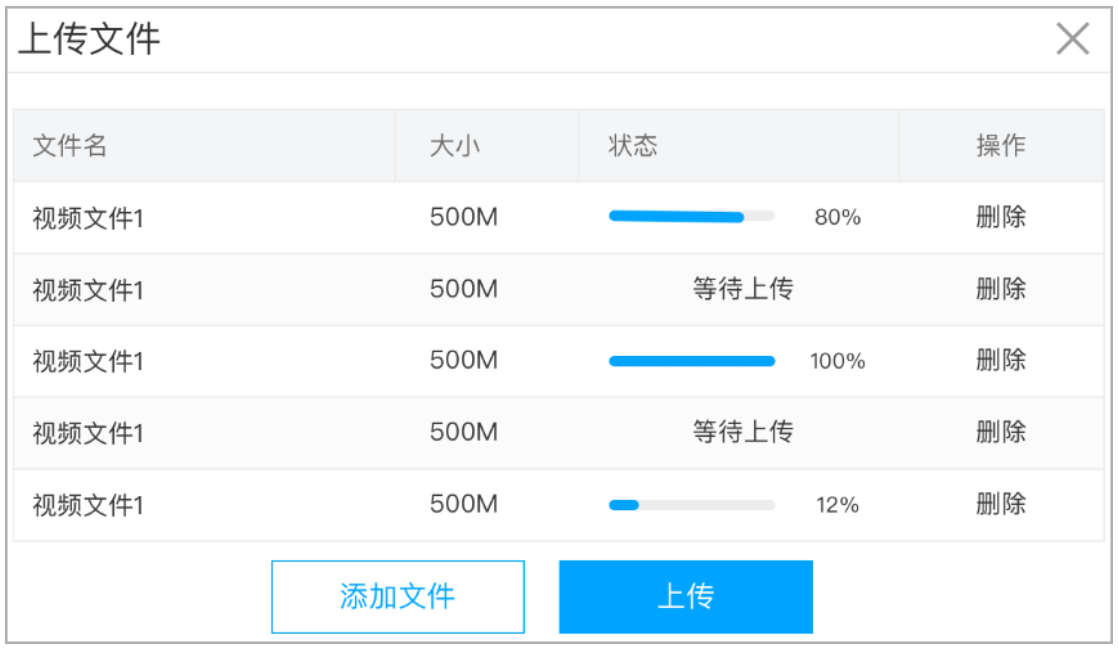

本篇完成的是前一条链路，并搭好后一条链路的调度基础。浏览器显示“上传 100%”只表示分块传输进度，最终成功还要等合并、完整性校验和入库。

| 阶段 | 主要参与者 | 结束时应具备的事实 |
|---|---|---|
| 文件识别 | 前端 | 得到整个文件的标识、大小和分块总数 |
| 分块传输 | 前端、媒资 API、MinIO | 所需分块在对象存储中存在 |
| 合并校验 | 媒资 Service、MinIO | 最终对象顺序正确、完整性验证通过 |
| 元信息入库 | 媒资 Service、MySQL | `media_files` 能查到对应对象信息 |
| 视频处理 | XXL-JOB、媒资执行器 | 07 继续实现转码与处理状态更新 |

**怎么记**：传完块 → 合并完整文件 → 校验 → 登记媒资 → 后台处理。文件成功落库与转码成功是两个阶段。


## 2. 分块上传、断点续传和秒传分别解决什么

分块上传把一个大文件拆成若干小请求，降低单次失败的重传成本。断点续传在再次上传时询问服务器哪些块已经存在，只补传缺失部分。秒传则在整个文件已经存储且当前用户可以使用时，直接复用现有资源。

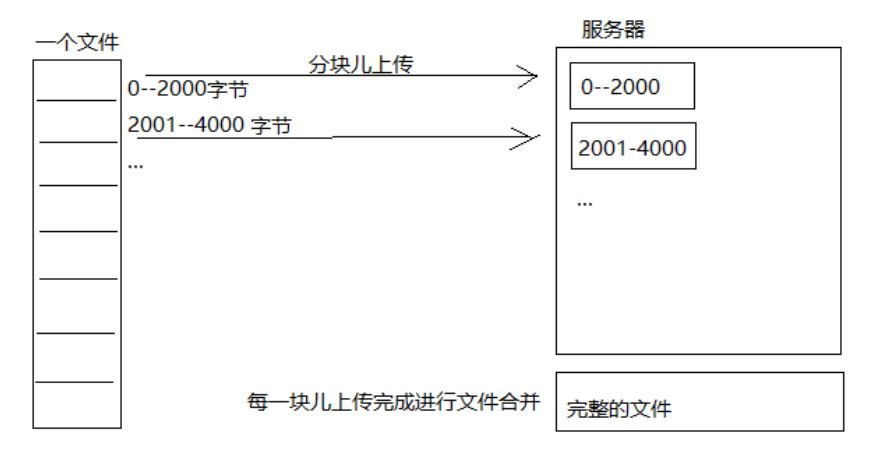

| 概念 | 判断对象 | 典型动作 |
|---|---|---|
| 分块上传 | 原始文件的多个字节区间 | 逐块或有限并发上传 |
| 断点续传 | 某一文件的已上传分块 | 查询已存在块，补传缺失块 |
| 秒传 | 已完成的整个文件 | 验证可复用后返回成功 |

讲义提到多线程上传，它是提高吞吐的可选方式，**实现断点续传不要求每一块必须使用一个线程**。顺序上传一样可以续传；并发上传需要限制并发量，避免网络、内存或对象存储连接耗尽。

课程采用“整文件 MD5 + 分块序号”定位分块。MD5 在这里承担文件标识与完整性检查的学习用途；它不能证明文件归属，也不是授权凭据。浏览器刷新后内存里的进度会丢失，恢复依据是服务端保存的分块。


## 3. 分块大小、序号和数量要形成一致约定

设原文件字节数为 `L`，每块最多 `S` 字节，则块数是向上取整的 `L / S`。可以用整数运算避免浮点误差：`L / S + (L % S == 0 ? 0 : 1)`。前提是 `S > 0`，课程示例可直接拒绝空文件。

| 约定 | 本课程写法 |
|---|---|
| 起始序号 | `0` |
| 最后序号 | `chunkTotal - 1` |
| 第 `i` 块起点 | `i * chunkSize` |
| 第 `i` 块结束位置 | `min((i + 1) * chunkSize, fileSize)`，右端不包含 |
| MinIO 合并实验分块 | `5 * 1024 * 1024` 字节，即 5 MiB |

例如一个 12 MiB 文件，以 5 MiB 分块，得到 `0、1、2` 三块，大小为 5 MiB、5 MiB、2 MiB。尾块小于正常块是合理的；总数与序号不能混用，`chunkTotal=3` 不代表存在序号 `3`。

**补充 / 校正**：前端常写“5MB”，应核对它实际使用的字节计算。5,000,000 字节小于 5 MiB 的 5,242,880 字节，可能触发 multipart 合并限制。所有客户端必须使用相同约定；生产扩展可以把分块大小、数量和原文件大小放到上传会话中，防止不同参数的块混在一起。


## 4. 用 RandomAccessFile 理解本地分块

讲义先在本地拆分文件，再把分块上传到 MinIO。这是原理实验；课程正式链路由前端分块，后端接收分块。

讲义的本地示例使用 1 MiB 分块和 1 KiB 缓冲区。学习时应保证“本块剩余字节数”限制每次读取量，避免配置的块大小不是缓冲区整数倍时多写字节。下面是校正版方法，使用 JDK 8：

```java
import java.io.EOFException;
import java.io.IOException;
import java.io.RandomAccessFile;
import java.nio.file.Files;
import java.nio.file.Path;

public static int splitFile(Path source, Path directory,
                            long chunkSize) throws IOException {
    long length = Files.size(source);
    if (length <= 0 || chunkSize <= 0) {
        throw new IllegalArgumentException("文件和分块大小必须大于零");
    }
    int total = Math.toIntExact(length / chunkSize
            + (length % chunkSize == 0 ? 0 : 1));
    Files.createDirectories(directory);
    byte[] buffer = new byte[8192];
    try (RandomAccessFile input =
                 new RandomAccessFile(source.toFile(), "r")) {
        for (int index = 0; index < total; index++) {
            Path part = directory.resolve(Integer.toString(index));
            long remaining = Math.min(chunkSize,
                    length - (long) index * chunkSize);
            try (RandomAccessFile output =
                         new RandomAccessFile(part.toFile(), "rw")) {
                output.setLength(0);
                while (remaining > 0) {
                    int size = (int) Math.min(buffer.length, remaining);
                    int read = input.read(buffer, 0, size);
                    if (read == -1) {
                        throw new EOFException("原文件在分块期间发生变化");
                    }
                    output.write(buffer, 0, read);
                    remaining -= read;
                }
            }
        }
    }
    return total;
}
```

需要理解的 API：`read()` 返回实际读到的字节数，`-1` 表示结束；`write(buffer, 0, read)` 只写有效数据；`setLength(0)` 截断上次同名块的旧内容；try-with-resources 关闭文件句柄。循环中发生异常后，本地可能留下不完整块，重试实验时应使用新的测试目录或明确覆盖全部目标块。


## 5. 本地合并的关键是按数字顺序和按总数读取

目录中的文件顺序没有保证。字符串排序会把 `10` 排在 `2` 前面；正确的顺序应是 `0、1、2……`。讲义使用按文件名转换为整数排序，下面直接按已知块数取文件，同时拒绝缺块。

```java
import java.io.IOException;
import java.io.InputStream;
import java.io.OutputStream;
import java.nio.file.Files;
import java.nio.file.Path;
import org.apache.commons.codec.digest.DigestUtils;

public static void mergeFiles(Path directory, int chunkTotal,
                              Path target) throws IOException {
    if (chunkTotal <= 0) {
        throw new IllegalArgumentException("分块数量必须大于零");
    }
    // target 应位于分块目录之外，并且不能等于任一分块文件。
    for (int index = 0; index < chunkTotal; index++) {
        if (!Files.isRegularFile(directory.resolve(Integer.toString(index)))) {
            throw new IOException("缺少分块 " + index);
        }
    }
    try (OutputStream output = Files.newOutputStream(target)) {
        for (int index = 0; index < chunkTotal; index++) {
            Files.copy(directory.resolve(Integer.toString(index)), output);
        }
    }
}

public static String md5(Path file) throws IOException {
    try (InputStream input = Files.newInputStream(file)) {
        return DigestUtils.md5Hex(input);
    }
}
```

实验时比较 `md5(source)` 与 `md5(target)`，再核对原文件和合并文件大小。`Files.newOutputStream` 的默认行为会截断已有目标文件；本地实验必须选一个明确的测试输出，避免覆盖原文件。

**怎么验证原理**：准备至少 12 块，使序号出现 `10`；删除其中一块，确认合并会失败；替换某块内容，确认最终 MD5 不一致。仅播放前几秒视频不能证明整个文件完整。


## 6. 课程怎样组织分块和最终对象路径

媒资 Service 用整个文件的 MD5 构造确定的对象名，把分块与最终对象放在相邻目录中。对象存储中的“目录”是对象 key 的前缀，不是本地文件夹。

```java
private String getChunkFileFolderPath(String fileMd5) {
    return fileMd5.substring(0, 1) + "/"
            + fileMd5.substring(1, 2) + "/"
            + fileMd5 + "/chunk/";
}

private String getFilePathByMd5(String fileMd5, String extension) {
    return fileMd5.substring(0, 1) + "/"
            + fileMd5.substring(1, 2) + "/"
            + fileMd5 + "/" + fileMd5 + extension;
}
```

若 MD5 为 `a12f4c8d9b0e1234567890abcdef1234`：

```text
video
└── a/1/a12f4c8d9b0e1234567890abcdef1234/
    ├── chunk/0
    ├── chunk/1
    ├── chunk/2
    └── a12f4c8d9b0e1234567890abcdef1234.avi
```

先校验 MD5 为 32 位十六进制并统一小写，再做 `substring`；`chunk` 需要非负且小于会话中的总数。文件名只用于显示，扩展名要由服务端检查，不能直接把用户传入的路径片段拼进对象名。

两层前缀便于组织与扫描对象，**不能据此断言会自动提升 MinIO 性能**。课程采用全局 MD5 命名；多机构同时上传同一文件时共享同一分块前缀，正式系统还需考虑机构、上传会话、覆盖和清理竞争。


## 7. MinIO composeObject 合并实验与 5 MiB 限制

先按块的真实数字名称上传，避免把 `listFiles()` 遍历位置当成块号。讲义的示例把遍历下标作为对象名，而文件数组的顺序没有保证，可能把原来的第 10 块放到对象 `chunk/2`。

```java
for (int index = 0; index < chunkTotal; index++) {
    Path part = chunkDirectory.resolve(Integer.toString(index));
    minioClient.uploadObject(UploadObjectArgs.builder()
            .bucket("testbucket")
            .object("chunk/" + index)
            .filename(part.toString())
            .build());
}

List<ComposeSource> sources = IntStream.range(0, chunkTotal)
        .mapToObj(index -> ComposeSource.builder()
                .bucket("testbucket")
                .object("chunk/" + index)
                .build())
        .collect(Collectors.toList());

minioClient.composeObject(ComposeObjectArgs.builder()
        .bucket("testbucket")
        .object("merge01.mp4")
        .sources(sources)
        .build());
```

这段是 SDK 操作片段，`minioClient`、`chunkDirectory`、`chunkTotal` 来自实验环境；Java 类型属于 `io.minio`、`java.nio.file`、`java.util`、`java.util.stream`。

讲义把 1 MiB 块用于合并时出现：`size 1048576 must be greater than 5242880`，因此改为 5 MiB。**校正**：multipart 的普通 part 要满足至少 5 MiB，最后一个 part 允许更小；不能为了满足限制给尾块随意补零，否则改变文件内容。官方 [MinIO SDK 8.4.3 的 S3Base](https://github.com/minio/minio-java/blob/8.4.3/api/src/main/java/io/minio/S3Base.java) 在 `calculatePartCountAsync` 中，明确对单一来源和最后一个来源留有例外；错误提示里的 greater than 也不能理解为必须严格大于 5 MiB。

`composeObject` 在对象存储端合并来源对象，业务 API 不必先把全部分块拉回本机拼接。但课程之后为计算整个文件 MD5 又下载最终对象，这仍然会占用后端网络与临时磁盘。


## 8. 四个上传接口与 RestResponse 的语义

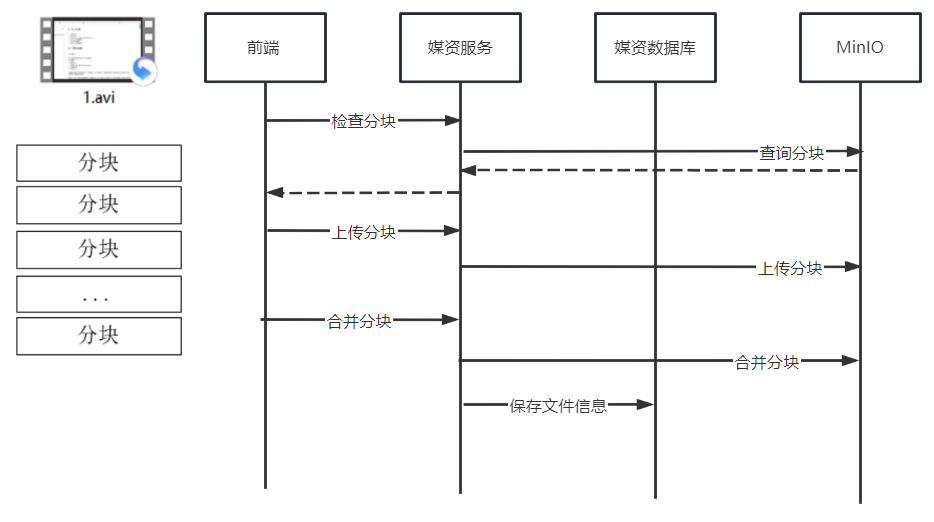

课程新增 `BigFilesController`。媒资 API 的上下文路径为 `/media`；因此 Controller 上的 `/upload/checkfile` 对外是 `/media/upload/checkfile`。网关保留该路径，不在此额外去掉 `/media`。

| 接口 | 方法 | 参数 | 含义 |
|---|---|---|---|
| `/upload/checkfile` | POST | `fileMd5` | 检查整个文件能否复用 |
| `/upload/checkchunk` | POST | `fileMd5`、`chunk` | 检查某个分块是否存在 |
| `/upload/uploadchunk` | POST | `file`、`fileMd5`、`chunk` | 接收并存储分块 |
| `/upload/mergechunks` | POST | `fileMd5`、`fileName`、`chunkTotal` | 合并、校验并保存媒资信息 |

前两个检查接口返回 `RestResponse<Boolean>`。讲义与前端约定：操作成功 `code=0`，失败 `code=-1`。存在与否放在 `result` 中：

```json
{"code": 0, "msg": "success", "result": false}
```

这是“检查成功，文件不存在”，前端应继续上传；不是接口失败。原类的三个字段是 `code、msg、result`；`isSuccessful()` 只判断 `code == 0`。上面的 JSON 展示这三个字段，实际序列化还可能包含该 getter 对应的派生属性。

**判断顺序**：先检查 `code`，再检查 `result`。HTTP 200 也不能直接解释为文件已存在；存储服务异常也不能轻易伪装为不存在。

课程 Controller 使用 `@RequestParam` 接收表单字段，上传分块字段名是 `file`，与上一天图片上传的 `filedata` 不同。参数名对不上会导致后端收不到文件。


## 9. 检查整文件需要同时看元信息和对象

讲义的 `checkFile(fileMd5)` 先通过 `mediaFilesMapper.selectById(fileMd5)` 查询 `media_files`，再按记录中的 bucket、filePath 去 MinIO 查对象。记录存在但对象丢失时，不能认为整文件已完成。

| MySQL 记录 | MinIO 最终对象 | 解释 |
|---|---|---|
| 有 | 有 | 可以继续检查状态与使用权限，再决定复用 |
| 有 | 没有 | 元信息与对象不一致，需要修复或重新上传 |
| 没有 | 有 | 可能是入库失败留下的对象，不能直接当成正常媒资 |
| 没有 | 没有 | 需要上传 |

原示例用 `getObject` 获取流检查存在，却没有关闭返回流。只取元信息时，`statObject` 更合适；网络不可达、凭据错误等也应区分处理。校正版方法片段：

```java
private boolean objectExists(String bucket, String objectName)
        throws Exception {
    try {
        minioClient.statObject(StatObjectArgs.builder()
                .bucket(bucket)
                .object(objectName)
                .build());
        return true;
    } catch (ErrorResponseException ex) {
        if ("NoSuchKey".equals(ex.errorResponse().code())) {
            return false;
        }
        throw ex;
    }
}
```

类型来自 `io.minio.StatObjectArgs` 和 `io.minio.errors.ErrorResponseException`。该片段按本课程 bucket 应预先存在的环境处理 `NoSuchKey`；其他错误上交异常层，不能把“桶不存在”或“访问被拒绝”吞掉。

**补充 / 校正**：课程以 MD5 为 `media_files.id`，全局复用会遇到跨机构归属问题。检查接口没有机构参数，不代表无需授权。当前机构应来自认证上下文；如采用底层对象去重，可以把“共享物理对象”和“机构自己的媒资记录”分开建模。


## 10. 检查分块是断点续传的恢复依据

`checkChunk(fileMd5, chunkIndex)` 按固定路径查对象：`getChunkFileFolderPath(fileMd5) + chunkIndex`，bucket 使用配置中的视频桶。存在时返回 `RestResponse.success(true)`，不存在时返回 `success(false)`。

重新选择同一文件后，前端重算或取得同一文件标识，遍历所有块，先检查再上传。浏览器保存的进度只便于显示，服务器查询结果决定是否能跳过该块。

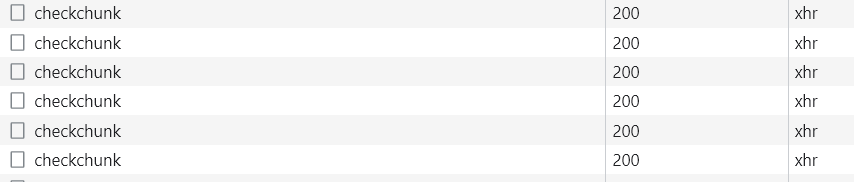

**存在检查的边界**：同名对象存在只证明这个 key 下有数据，不自动证明它属于当前上传会话、字节数正确、内容未变化。课程靠最终 MD5 作兜底；扩展实现可记录分块大小、分块摘要和会话参数，在检查时校验。检查成功后到正式使用之间仍可能发生变化，因此合并阶段要重新确认。

并发客户端上传同一个 MD5 的不同分块参数，会相互覆盖或混用。引入 `uploadId` 或上传会话后，可把对象路径改为“机构 / uploadId / chunkIndex”；这里是补充设计，不是声称讲义已经实现。


## 11. 上传分块时统一文件参数并回收临时文件

讲义中有两个版本：`uploadChunk(..., byte[] bytes)` 与 `uploadChunk(..., String localFilePath)`。一些 Controller 示例传临时文件路径，另一些调用 `file.getBytes()`，Service 声明却仍是字节数组。复现时必须选定一种签名，让 Controller、接口、实现一致。

本篇以临时文件路径版本说明，与第 05 天文件上传方式衔接：

```java
// MediaFileService 中与实现保持一致的声明
RestResponse<Boolean> uploadChunk(String fileMd5, int chunk,
                                  String localFilePath);
```

Controller 方法示例，所在类需要 `@RestController` 和已注入的 `mediaFileService`：

```java
@PostMapping("/upload/uploadchunk")
public RestResponse<Boolean> uploadchunk(
        @RequestParam("file") MultipartFile file,
        @RequestParam("fileMd5") String fileMd5,
        @RequestParam("chunk") int chunk) throws Exception {
    if (file.isEmpty() || chunk < 0
            || !fileMd5.matches("[0-9a-f]{32}")) {
        return RestResponse.validfail(false, "分块参数不正确");
    }
    Path temporary = Files.createTempFile("media-chunk-", ".part");
    try {
        file.transferTo(temporary.toFile());
        return mediaFileService.uploadChunk(
                fileMd5, chunk, temporary.toString());
    } finally {
        try {
            Files.deleteIfExists(temporary);
        } catch (IOException ex) {
            log.warn("临时分块清理失败: {}", temporary, ex);
        }
    }
}
```

该方法是参数和清理演示，完整实现还需在上传会话中检查 `chunk < chunkTotal`、实际大小、机构归属和过期时间。日志使用所在类的 Lombok `@Slf4j`；导入 `RestResponse`、Spring Web 注解、`MultipartFile`、`java.nio.file.Files/Path`、`java.io.IOException`。

Service 用 `bucket_videoFiles` 与稳定的对象 key 调用 MinIO，例如：

```java
minioClient.uploadObject(UploadObjectArgs.builder()
        .bucket(bucket_videoFiles)
        .object(getChunkFileFolderPath(fileMd5) + chunk)
        .filename(localFilePath)
        .build());
return RestResponse.success(true);
```

`getBytes()` 会把分块完整装进 Java 堆；多个并发请求会累加内存占用。路径方式避免这一次全量 byte[] 拷贝，但也需要容量控制和磁盘清理。讲义上传分块方法的 `catch (Exception ex)` 内使用 `e.getMessage()` 是变量名错误，应改为 `ex.getMessage()`。


## 12. 50MB 配置限制的是单次请求

讲义指出，Spring Boot Web 默认文件上传限制可能比 5 MiB 分块更小。媒资 API 要配置 Multipart 上限：

```yaml
spring:
  servlet:
    multipart:
      max-file-size: 50MB
      max-request-size: 50MB
```

| 配置 | 限制对象 |
|---|---|
| `max-file-size` | 一个 multipart 文件字段 |
| `max-request-size` | 一次 multipart HTTP 请求的总大小 |

一个 1 GiB 视频分成 5 MiB 块，逐块发送，每次请求满足上限即可。把这两个配置调到 1 GiB 并不能自动获得断点续传。请求总大小还包括表单字段、边界等，不建议刚好等于块的大小。

配置应放到实际启动的 `media-api` 对应配置环境，检查 namespace、group、Data ID、profile 是否匹配。已有导出配置的 `media-api-dev.yaml` 只包含端口与 `/media` 路径，这个 Multipart 配置需要补充。直接调用 API 成功而通过网关失败时，再检查 Gateway、反向代理的请求限制和超时。


## 13. 合并前要重新确认全部分块

前端说“全部传完”只是一条请求，服务端不能以此替代校验。合并参数要来自可信上传会话或经过一致性验证，再按 `0` 到 `chunkTotal - 1` 构造来源列表。

```java
List<ComposeSource> sources = new ArrayList<>();
for (int index = 0; index < chunkTotal; index++) {
    String objectName = getChunkFileFolderPath(fileMd5) + index;
    StatObjectResponse part = minioClient.statObject(
            StatObjectArgs.builder()
                    .bucket(bucket_videoFiles)
                    .object(objectName)
                    .build());
    if (part.size() <= 0) {
        throw new IllegalStateException("分块内容为空: " + index);
    }
    sources.add(ComposeSource.builder()
            .bucket(bucket_videoFiles)
            .object(objectName)
            .build());
}
String mergedObject = getFilePathByMd5(fileMd5, extension);
minioClient.composeObject(ComposeObjectArgs.builder()
        .bucket(bucket_videoFiles)
        .object(mergedObject)
        .sources(sources)
        .build());
```

这是合并流程片段；还应验证普通块与尾块的预期大小，而不仅是非空。`chunkTotal` 需要正数和合理上限，扩展名要先验证。对象存储的 part 数、单块和最终文件大小存在边界，不能让客户端传入任意巨大的总数后直接 `limit()` 或创建集合。

讲义用 `Stream.iterate(0, i -> ++i).limit(chunkTotal)` 得到相同顺序；`IntStream.range(0, chunkTotal)` 更直接。来源列表的顺序决定最终内容顺序，与块实际上传完成的先后无关。

MinIO 的合并不锁住本项目的上传会话。另一个请求仍可能覆盖来源对象；需要会话状态、互斥或版本条件把“继续上传”和“正在合并”协调起来。合并结束并不代表数据库也已经提交。


## 14. 合并后计算整文件 MD5

讲义把合并对象下载到临时文件，计算 `DigestUtils.md5Hex(input)`，与客户端提供的整文件 MD5 比较。通过后用实际文件大小填充上传 DTO，再保存媒资记录。

下面用 SDK `downloadObject` 演示获取本地临时文件与校验，异常由上层转换为业务失败：

```java
Path merged = Files.createTempFile("media-merged-", ".tmp");
try {
    minioClient.downloadObject(DownloadObjectArgs.builder()
            .bucket(bucket_videoFiles)
            .object(mergedObject)
            .filename(merged.toString())
            .overwrite(true)
            .build());
    String actualMd5;
    try (InputStream input = Files.newInputStream(merged)) {
        actualMd5 = DigestUtils.md5Hex(input);
    }
    if (!fileMd5.equals(actualMd5)) {
        throw new IllegalStateException("合并后的文件校验失败");
    }
    uploadFileParamsDto.setFileSize(Files.size(merged));
} finally {
    try {
        Files.deleteIfExists(merged);
    } catch (IOException ex) {
        log.warn("临时合并文件清理失败: {}", merged, ex);
    }
}
```

`DownloadObjectArgs` 属于 MinIO SDK；整个片段放在能访问对应变量的 Service 方法中。若沿用讲义的 `getObject + IOUtils.copy`，输入流和输出流都应使用 try-with-resources；不能只关闭输出流。

**校验不通过后的处理**：不入库、不声明上传成功，保留或隔离分块以便排查，并清理本次产生的不完整合并对象。讲义流程图提到“不完整则删除文件”，但正文示例只是返回失败、清理本地临时文件，没有完整的合并对象删除实现。正式系统清理前还需验证对象属于本次会话，防止并发合并时删除别人的成功结果。

不要把 multipart 对象的 ETag 无条件当成整文件 MD5；整文件摘要也不是“每块 MD5 字符串拼起来再计算”。课程采用下载校验方法，代价是后端再次传输完整文件。


## 15. 元信息入库和事务代理

`mergechunks` 接收 `companyId、fileMd5、chunkTotal、UploadFileParamsDto`。Controller 的讲义示例暂时使用 `1232141425L`，DTO 设置文件类型 `001002`、标签“课程视频”、文件名等。完成校验后调用：

```java
currentProxy.addMediaFilesToDb(companyId, fileMd5,
        uploadFileParamsDto, bucket_videoFiles, mergedObject);
```

`addMediaFilesToDb` 的作用是记录文件 ID、机构、桶、对象路径、文件大小、类型、审核状态和 URL 等；具体字段沿用第 05 天的 `MediaFiles` 模型。视频在后续处理中可能生成新的播放地址，上传完成的原始地址不等于最终播放地址。

Spring 基于代理应用 `@Transactional`。如果同一个 Bean 中直接用 `this.addMediaFilesToDb(...)`，默认代理机制下不会进入该方法的事务拦截。讲义通过注入代理对象 `currentProxy` 调用；独立的入库 Service Bean 是另一种组织方式。

**事务顺序**：MinIO 合并和校验成功 → 经代理调用数据库事务 → 提交成功 → 清理分块。把耗时合并放在长数据库事务里会占用数据库连接；数据库回滚也不会撤销已写入 MinIO 的对象。

讲义用文件 MD5 查重，但“先查询再插入”无法排除并发插入；应依赖唯一约束并处理冲突。幂等返回必须同时确认对象、记录状态和机构关系，不能看到主键存在就宣称整个上传已成功。


## 16. 合并成功后清理分块

讲义用 `removeObjects` 删除 `chunk/0` 至 `chunk/(chunkTotal-1)`。它返回惰性结果迭代器，必须遍历并调用 `get()` 才能取得删除结果或异常；成功调用函数本身不代表每个对象都删掉了。

```java
List<DeleteObject> objects = IntStream.range(0, chunkTotal)
        .mapToObj(index -> new DeleteObject(
                getChunkFileFolderPath(fileMd5) + index))
        .collect(Collectors.toList());

Iterable<Result<DeleteError>> results = minioClient.removeObjects(
        RemoveObjectsArgs.builder()
                .bucket(bucket_videoFiles)
                .objects(objects)
                .build());
for (Result<DeleteError> result : results) {
    try {
        DeleteError error = result.get();
        log.warn("删除分块失败: {}, {}",
                error.objectName(), error.message());
    } catch (Exception ex) {
        log.warn("读取分块删除结果失败", ex);
    }
}
```

类型包含 `io.minio.Result`、`io.minio.messages.DeleteObject/DeleteError`。代码返回的各项是删除错误，正常删除可能不会逐个返回成功项。

**讲义校正**：原方法写死 `.bucket("video")`，应统一使用实际视频桶配置；`catch` 中访问尚未赋值的 `deleteError.objectName()` 可能再触发空指针；打印异常也不能替代检查 `DeleteError` 本身。

删除分块失败时，完整文件和元信息可能已经成功。应记录清理任务稍后重试，不必把一个可正常使用的文件简单标记为“上传失败”。清理的时机应晚于有效元信息的提交，避免数据库失败后连可恢复的来源块也丢失。


## 17. 上传链路的 HTTP 联调顺序

下面是直连媒资 API 的学习请求，默认端口 `63050`、路径 `/media`。使用浏览器前端时，先确认实际前端代理或网关地址；不要把前端开发服务器端口误当成媒资服务端口。

```http
### 1. 整文件检查
POST http://localhost:63050/media/upload/checkfile
Content-Type: application/x-www-form-urlencoded

fileMd5=a12f4c8d9b0e1234567890abcdef1234

### 2. 分块检查
POST http://localhost:63050/media/upload/checkchunk
Content-Type: application/x-www-form-urlencoded

fileMd5=a12f4c8d9b0e1234567890abcdef1234&chunk=0

### 3. 上传第 0 块，文件内容由 HTTP 客户端读取
POST http://localhost:63050/media/upload/uploadchunk
Content-Type: multipart/form-data; boundary=Day06Boundary

--Day06Boundary
Content-Disposition: form-data; name="fileMd5"

a12f4c8d9b0e1234567890abcdef1234
--Day06Boundary
Content-Disposition: form-data; name="chunk"

0
--Day06Boundary
Content-Disposition: form-data; name="file"; filename="0"
Content-Type: application/octet-stream

< ./chunk/0
--Day06Boundary--

### 4. 全部 3 块上传后合并
POST http://localhost:63050/media/upload/mergechunks
Content-Type: application/x-www-form-urlencoded

fileMd5=a12f4c8d9b0e1234567890abcdef1234&fileName=lesson.avi&chunkTotal=3
```

MD5 是占位示例，需要替换为实际原文件的摘要；示例只演示一块上传，第 1、2 块也应上传后再合并。`< ./chunk/0` 是支持该语法的 HTTP 客户端读取文件指令，不是发送给服务器的文字。

用较大视频上传一部分，暂停并刷新浏览器，再重新选同一文件：观察 Network 中的 `checkchunk` 返回值，确认已存在块不再执行 `uploadchunk`。随后查看最终对象、数据库记录和返回结果。讲义原图提供的请求列表只是续传演示，HTTP 200 本身不能证明所有内容已校验成功。


## 18. 放弃上传留下的分块怎样回收

合并后的清理只能覆盖成功上传。用户传到一半关闭页面，未完成的块仍在 MinIO；长期累积会浪费存储。

讲义给出设计思路：开始上传时登记“上传中”，完成后改为“上传完成”，定时查找未完成记录，删除其分块目录。这个方案需要补充上传开始记录和状态维护；第 05 天的 `media_files` 表主要保存已经上传的文件，不能仅凭现有上传后入库代码，就声称具备完整的未完成上传回收功能。

**补充设计**：建立上传会话，例如记录 `uploadId、companyId、fileMd5、chunkSize、chunkTotal、fileSize、status、lastActivityTime、expireTime`。状态可设计为 UPLOADING、MERGING、COMPLETE、CLEANING、EXPIRED，属于扩展方案，不能直接当作课程数据库原有枚举。

清理任务应先原子认领“已超时且仍未完成”的会话，再删除该会话自己的对象，最后记录结果。上传请求同时更新活动时间并拒绝 CLEANING / EXPIRED 状态，才能减少“用户正在续传，定时任务删块”的竞争。

不要直接用“块的创建时间很久以前”作为清理依据，也不要删除整个全局 MD5 目录而连带删除最终对象。生命周期策略可以帮助回收专用临时前缀，但仍要与允许续传的有效期配合。下一部分的 XXL-JOB 可以承载回收任务，今天先完成调度能力接入。


## 19. 上传链路容易踩的坑

| 现象 | 常见原因 | 检查位置 |
|---|---|---|
| 续传仍然从第 0 块重传 | 文件标识变化、检查返回值判断错误、块路径不一致 | 前端 MD5、`code/result`、桶和对象 key |
| 某些视频合并失败 | 分块过小、缺块、顺序错、尾块参数不一致 | 分块字节数、对象列表、合并源顺序 |
| HTTP 400 或没有收到文件 | 参数名使用 `filedata`，或把表单当 JSON 发送 | Controller 注解与请求 Content-Type |
| 上传时被拒绝 | Multipart 上限或代理限制 | API、网关、反向代理配置 |
| 文件能找到但列表没有记录 | MinIO 成功后数据库事务失败 | 入库异常、唯一约束、事务代理 |
| 有数据库记录却不能访问 | 桶或对象丢失、URL 路径错误 | `bucket/file_path/url` 与实际对象 |
| 成功后分块残留 | 删除结果未遍历、桶写死、清理失败未重试 | `removeObjects` 的结果和日志 |
| 临时磁盘持续变大 | Controller 临时文件、下载临时文件未回收 | finally、输入输出流、失败路径 |

讲义示例还存在几处不一致：上传方法在 `byte[]` 与本地路径之间切换；`catch(ex)` 却使用 `e`；下载方法只关闭输出流；清理方法的错误对象可能为空。笔记中的代码采用统一接口或标注片段前提，复现时应按实际工程调整。

**排查方法**：沿“参数 → 分块对象 → 最终对象 → 摘要 → 数据记录”依次验证。一开始就增大所有超时、忽略异常或取消校验，会掩盖真正的失败阶段。


## 20. 从单机定时任务理解调度

任务调度是在给定时间点、间隔或规则到来时自动执行业务，例如每天生成报表、定期备份、回收过期分块。调度决定何时触发，业务方法决定触发后做什么。

| 方式 | 适用范围 | 需要理解的边界 |
|---|---|---|
| 线程循环 + sleep | 演示最基本的轮询 | 间隔受执行耗时影响，需要自己处理异常、停止和恢复 |
| Timer | 简单单机定时 | 同一 Timer 主要由一个线程串行执行；慢任务影响后续任务 |
| ScheduledExecutorService | 单机线程池定时 | 适合相对时间调度，不自带跨机器协调和管理界面 |
| Quartz | 复杂日历规则和持久化调度 | 具备 Job、Trigger、Scheduler；集群需要正确配置 |
| XXL-JOB | 集中管理多个执行器和任务 | 具备管理界面、远程调度、路由、日志与分片广播 |

讲义给出的 JDK 示例可以改成 lambda：

```java
ScheduledExecutorService scheduler = Executors.newScheduledThreadPool(2);
scheduler.scheduleAtFixedRate(() -> {
    try {
        System.out.println("执行一次任务");
    } catch (RuntimeException ex) {
        // 根据业务记录错误或中止，不要无声吞掉异常。
        ex.printStackTrace();
    }
}, 1, 2, TimeUnit.SECONDS);
// 应用关闭时执行 scheduler.shutdown()。
```

导入 `java.util.concurrent.Executors/ScheduledExecutorService/TimeUnit`。`scheduleAtFixedRate` 以计划开始时间为基准；`scheduleWithFixedDelay` 从上次执行结束后再等待指定间隔。

**讲义校正**：线程池允许不同任务并发，但同一个通过 `scheduleAtFixedRate` 注册的周期任务不会因执行超时而自动重叠执行。任务未捕获异常时，其后续周期执行可能被抑制。线程池也要有关闭机制，不能把创建线程池等同于处理完全部调度问题。


## 21. 多实例部署为什么需要协调任务

单机程序部署到三台机器后，每台机器中的本地定时器都可能触发。如果任务是发优惠券，就可能发三次；如果任务是处理同一个视频，就会浪费算力并争抢结果。

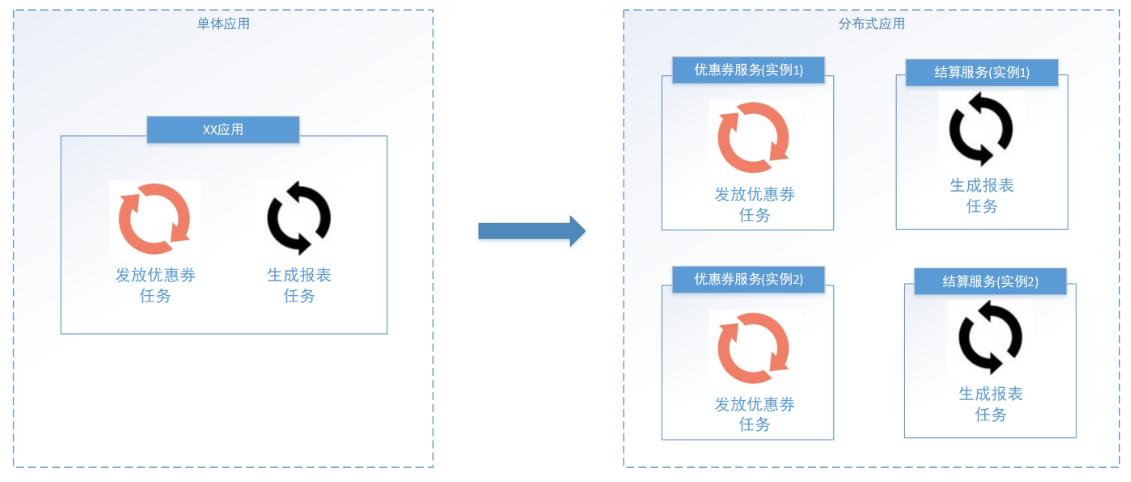

分布式任务调度要解决的主要问题是：用多台机器共同分担业务，某台机器故障后仍能继续工作，支持增加执行器，集中观察触发与执行状态，并协调任务重复执行。

“调度只路由到一台机器”和“业务永远只执行一次”不是同一保证。超时重试、重复调度、旧执行器尚未退出、机器扩缩容等情况仍可能产生重复业务执行。写入业务结果时必须保留幂等或原子认领手段。

分布式任务与多线程可以结合：不同执行器处理不同批次，每个执行器内部用有界并发处理。但增加执行器只能缓解可并行部分的瓶颈，数据库查询、磁盘、对象存储和单个视频转码也可能成为限制，不能承诺执行器数量翻倍就耗时减半。


## 22. XXL-JOB 的调度中心、执行器与任务

本项目使用 **XXL-JOB 2.3.1**。学习时对照这个版本，避免把旧版 `IJobHandler` 或新版本示例与课程的 `@XxlJob` 写法混在一起。

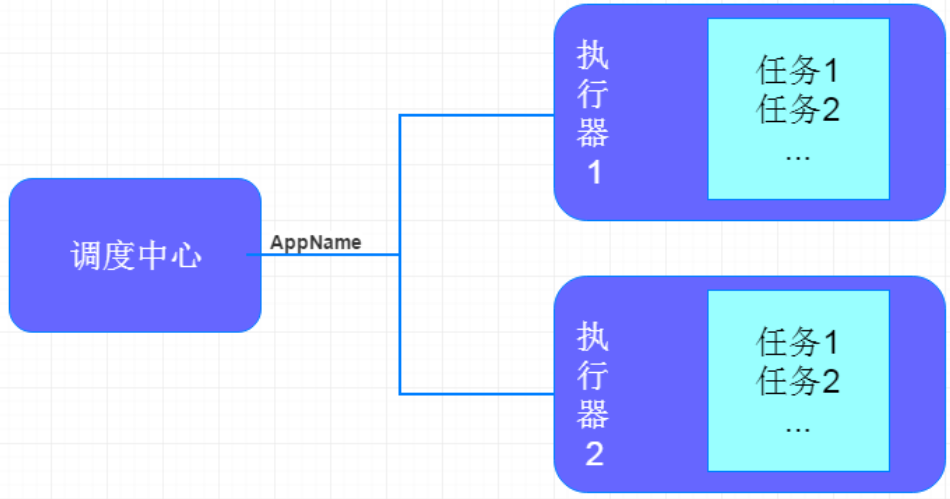

| 角色 | 负责什么 | 在学成在线中的位置 |
|---|---|---|
| 调度中心 Admin | 执行器分组、任务配置、触发、日志与监控 | 独立部署的 `xxl-job-admin` |
| 执行器 Executor | 注册地址、接收调度、调用任务、上报结果、读取日志 | 媒资应用中的 `XxlJobSpringExecutor` |
| 任务 JobHandler | 执行具体业务方法 | Spring Bean 中被 `@XxlJob` 标记的方法 |

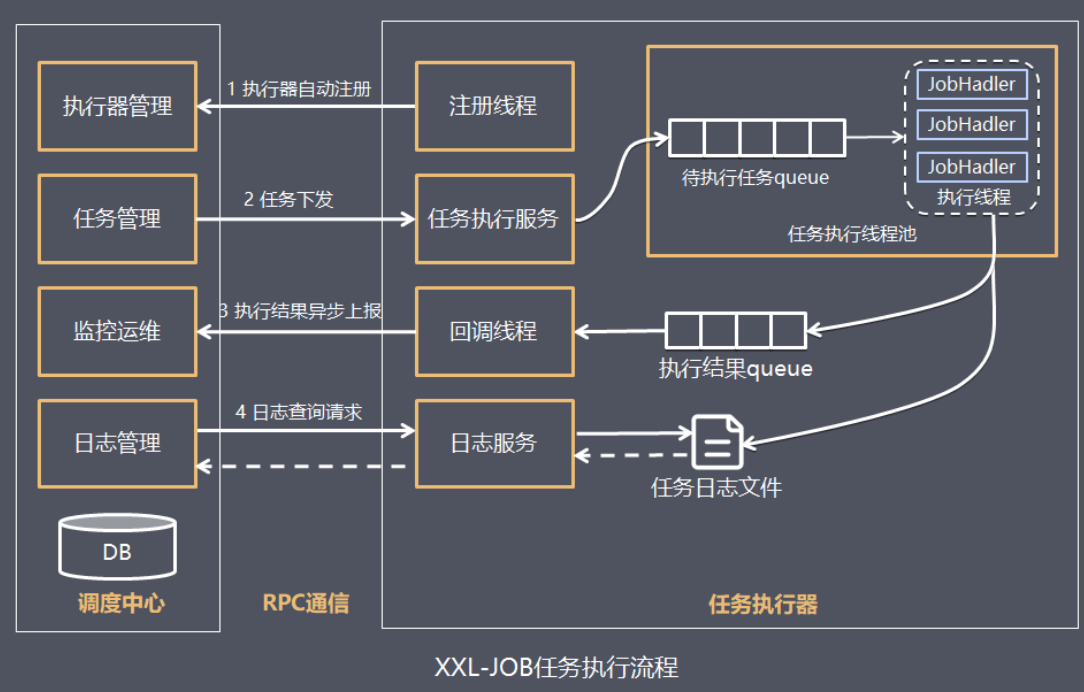

工作流程：执行器使用配置的 Admin 地址注册 → 时间规则到来，Admin 向执行器发送触发请求 → 执行器调用 Handler → 执行器报告结果 → 用户查看日志时，Admin 再向执行器读取任务日志。

**网络要双向可达**：执行器能访问 Admin，不代表 Admin 能访问执行器。开发环境常出现本机自动选了错误网卡、注册了 `127.0.0.1`、容器内部 IP 或只对本机可见的端口；此时“注册成功”仍可能伴随“调度失败”或“查看日志失败”。

执行器 appname 与 Nacos 的服务名不是同一个概念。`spring.application.name=media-api` 用于应用 / 服务发现；`xxl.job.executor.appname=media-process-service` 用于 XXL-JOB 的执行器分组，二者可以不同。


## 23. 2.3.1 调度中心与数据库准备

网盘提供 `xxl-job-2.3.1.zip`；也可以对照 [官方 2.3.1 发布版本](https://github.com/xuxueli/xxl-job/releases/tag/2.3.1)。目录中主要包含：

| 模块或目录 | 用途 |
|---|---|
| `xxl-job-admin` | 调度中心 Web 应用 |
| `xxl-job-core` | 执行器和调度通信的公共依赖 |
| `xxl-job-executor-samples` | Spring Boot、无框架等执行器示例 |
| `doc/db/tables_xxl_job.sql` | 初始化调度中心表结构和基础数据 |

讲义虚拟机已准备 `xxl_job_2.3.1` 数据库，Admin 地址是 `http://192.168.101.65:8088/xxl-job-admin/`，演示账号为 `admin/123456`。它们是课程环境约定；本机运行时应以自己的服务和数据库配置为准。

官方 [2.3.1 Admin 配置](https://github.com/xuxueli/xxl-job/blob/2.3.1/xxl-job-admin/src/main/resources/application.properties) 默认 Web 端口为 `8080`、数据库示例名为 `xxl_job`。**8088 是课程部署地址，不能据此认为下载源码默认也监听 8088。**

本机调整配置片段可以写为：

```properties
server.port=8088
server.servlet.context-path=/xxl-job-admin
spring.datasource.url=jdbc:mysql://localhost:3306/xxl_job?useUnicode=true&characterEncoding=UTF-8&serverTimezone=Asia/Shanghai
spring.datasource.username=${XXL_DB_USERNAME}
spring.datasource.password=${XXL_DB_PASSWORD}
xxl.job.accessToken=${XXL_JOB_TOKEN}
```

用相应版本脚本初始化实际数据库，再让 JDBC URL 指向该库。不要把讲义中的数据库名、源码默认库名和自己的导入库混用。Admin 数据库包含任务、分组、注册、日志等表；它不替代媒资的 `media_process` 业务任务表。

复现时先验证 Admin 能打开、数据库连接正常，再接入执行器。本篇仅整理步骤，没有启动 Admin、运行课程的 `restart.sh` 或执行初始化 SQL。


## 24. 在媒资服务中配置执行器

讲义在 `xuecheng-plus-media-service` 引入依赖，父工程约定版本 2.3.1：

```xml
<dependency>
    <groupId>com.xuxueli</groupId>
    <artifactId>xxl-job-core</artifactId>
</dependency>
```

如果自己的父工程没有 dependencyManagement，再明确添加 `<version>2.3.1</version>`。课程 API 依赖 Service，启动媒资 API 时会加载执行器 Bean；Service 是业务库模块，不能把“单独运行 Service 模块”当成已存在独立启动类的事实。

配置在本课程的 Nacos `media-service-dev.yaml` 中，原导出包已经包含：

```yaml
xxl:
  job:
    admin:
      addresses: http://192.168.101.65:8088/xxl-job-admin
    accessToken: default_token
    executor:
      appname: media-process-service
      address: ""
      ip: ""
      port: 9999
      logpath: /data/applogs/xxl-job/jobhandler
      logretentiondays: 30
```

| 配置 | 要核对的事实 |
|---|---|
| `admin.addresses` | 从执行器能访问的 Admin 基础地址，含上下文路径 |
| `accessToken` | 与 Admin 配置一致，课程默认是 `default_token` |
| `executor.appname` | 与 Admin 新增执行器的 AppName 完全一致 |
| `executor.address` | 显式指定注册给 Admin 的完整执行器地址，可按需填写 |
| `executor.ip` | 自动发现错误网卡时，指定可被 Admin 访问的 IP |
| `executor.port` | 执行器通信端口；不是媒资 HTTP API 的 63050 |
| `executor.logpath` | 执行器写任务日志的本机目录，必须可写 |
| `executor.logretentiondays` | 执行器日志保留天数，课程示例是 30 |

Windows 学习环境可把日志路径改为自己的可写目录，例如 `D:/xuecheng/logs/xxl-job`。两个不同机器都使用 `9999` 可以正常工作；同一台机器的两个执行器进程不能争用同一个端口。

第 05 天项目 bootstrap 示例的 Nacos namespace 为 `dev402`，而讲义示范还出现 `dev`。继续使用已建立的实际 namespace；若放错配置环境，执行器可能因缺少配置而失败，或注册到意外地址。生产配置应按实际环境管理 Token，这里的 `default_token` 是课件演示值。


## 25. XxlJobConfig 要真正创建 Spring 执行器 Bean

仅添加依赖和 YAML 不会自动获得课程的执行器。讲义要求从官方 sample 复制 `XxlJobConfig`，放到 `com.xuecheng.media.config`，并保证启动类的组件扫描范围覆盖它。

下面按 [官方 2.3.1 XxlJobConfig](https://github.com/xuxueli/xxl-job/blob/2.3.1/xxl-job-executor-samples/xxl-job-executor-sample-springboot/src/main/java/com/xxl/job/executor/core/config/XxlJobConfig.java) 整理，空地址与 IP 使用默认值：

```java
package com.xuecheng.media.config;

import com.xxl.job.core.executor.impl.XxlJobSpringExecutor;
import org.springframework.beans.factory.annotation.Value;
import org.springframework.context.annotation.Bean;
import org.springframework.context.annotation.Configuration;

@Configuration
public class XxlJobConfig {
    @Value("${xxl.job.admin.addresses}")
    private String adminAddresses;
    @Value("${xxl.job.accessToken}")
    private String accessToken;
    @Value("${xxl.job.executor.appname}")
    private String appname;
    @Value("${xxl.job.executor.address:}")
    private String address;
    @Value("${xxl.job.executor.ip:}")
    private String ip;
    @Value("${xxl.job.executor.port}")
    private int port;
    @Value("${xxl.job.executor.logpath}")
    private String logPath;
    @Value("${xxl.job.executor.logretentiondays}")
    private int logRetentionDays;

    @Bean
    public XxlJobSpringExecutor xxlJobExecutor() {
        XxlJobSpringExecutor executor = new XxlJobSpringExecutor();
        executor.setAdminAddresses(adminAddresses);
        executor.setAccessToken(accessToken);
        executor.setAppname(appname);
        executor.setAddress(address);
        executor.setIp(ip);
        executor.setPort(port);
        executor.setLogPath(logPath);
        executor.setLogRetentionDays(logRetentionDays);
        return executor;
    }
}
```

Spring 管理 Bean 的生命周期，执行器启动时注册任务 Handler 并启动通信。Admin 的“执行器管理”中，新增 AppName 为 `media-process-service`，选择自动注册。应用成功注册后，应能看到在线机器地址。

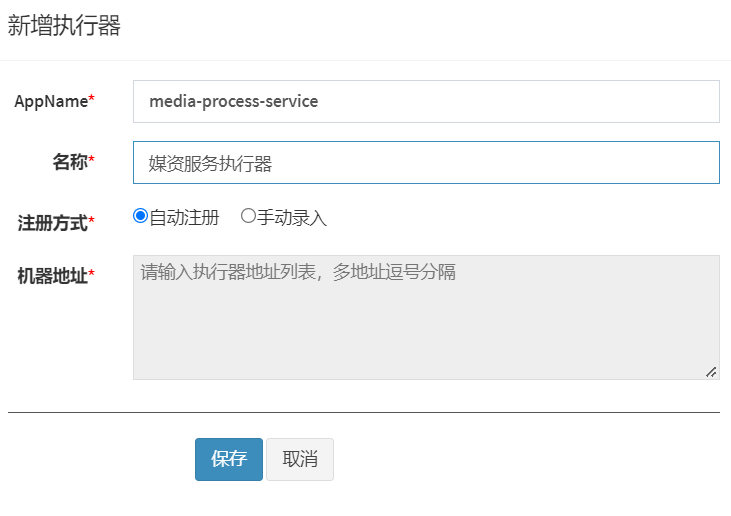

**先验证三件事**：Bean 确实被扫描创建；`9999` 端口成功监听；Admin 中的在线机器地址是它能访问的地址。再去验证具体任务，避免先排查业务 SQL，却实际连执行器都没有运行。


## 26. 用 @XxlJob 定义 BEAN 任务

在媒资 Service 的 `jobhandler` 包创建 Spring Bean。下面是接近官方 2.3.1 sample 的最小任务：

```java
package com.xuecheng.media.service.jobhandler;

import com.xxl.job.core.context.XxlJobHelper;
import com.xxl.job.core.handler.annotation.XxlJob;
import org.springframework.stereotype.Component;

@Component
public class SampleJob {
    @XxlJob("testJob")
    public void testJob() {
        XxlJobHelper.log("开始执行 testJob");
        // 在此同步执行本次任务的业务逻辑。
        XxlJobHelper.log("testJob 执行结束");
    }
}
```

`@XxlJob("testJob")` 的字符串是注册的 Handler 标识。Admin 的 JobHandler 填这个标识；不要求它一定与 Java 方法名相同，但相同更容易维护。Handler 应是被 Spring 扫描的 Bean，同一执行器不要重复使用相同标识。

官方 [2.3.1 SampleXxlJob](https://github.com/xuxueli/xxl-job/blob/2.3.1/xxl-job-executor-samples/xxl-job-executor-sample-springboot/src/main/java/com/xxl/job/executor/service/jobhandler/SampleXxlJob.java) 明确使用 `XxlJobHelper.log` 写任务日志。普通 `log.info` 主要进入应用日志，不保证在 Admin 的任务日志详情中形成同样的输出；可以根据需要同时记录。

默认执行结果为成功；需要表示业务失败时，可以抛异常，或调用 `XxlJobHelper.handleFail("失败原因")`。不能捕获所有异常后正常返回，让调度中心显示成功。创建异步线程后立即返回也可能导致 Handler 结束时业务尚未完成；后续视频任务需要明确等待、超时和结果上报方式。

**验证顺序**：应用重启并注册 Handler → Admin 创建 BEAN 任务 → 手动“执行一次” → 查看执行器与 Admin 日志 → 再启用周期调度。手动执行能验证通信和 Handler，不用先等待 Cron 时间。


## 27. 创建任务和正确阅读 Cron

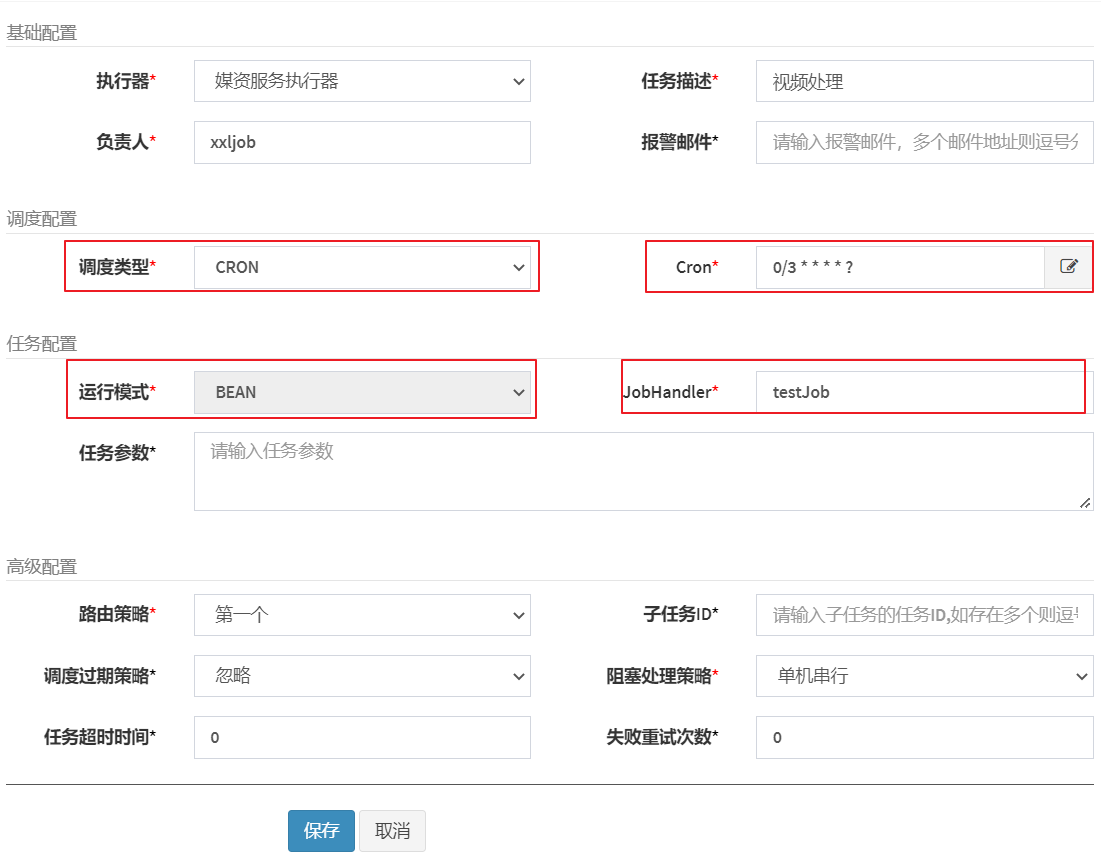

在 Admin 任务管理中新增：选择媒资执行器、填写说明和负责人、设置调度类型、运行模式 `BEAN`、JobHandler `testJob`。初次实验路由策略可选第一个，确认一个实例能正常执行后再切换分片广播。

XXL-JOB 2.3.1 使用带秒的 Cron，字段为：`秒 分 时 日 月 周 [年]`。不要直接拿 Unix crontab 的五字段表达式套用。

| Cron | 含义 |
|---|---|
| `30 10 1 * * ?` | 每天 01:10:30 |
| `0/30 * * * * ?` | 每分钟的第 0、30 秒触发 |
| `0 0/10 * * * ?` | 每小时第 0、10、20、30、40、50 分钟的第 0 秒触发 |
| `0 0 1 1 * ?` | 每月 1 日 01:00:00 |

**讲义校正**：把 `* 0/10 * * * ?` 解释成“每 10 分钟触发一次”不准确。它会在分钟为 0、10、20……时，每秒触发；应把秒字段改成 `0`。`?` 表示该日 / 周字段不指定具体值，通常在日和周只约束一方。

Cron 表达的是日历规则，触发时区应以调度中心实际配置和运行环境验证。学习配置先使用短间隔，观察日志确认后停止任务，避免持续生成无意义日志。

| 高级配置 | 决定什么 | 注意事项 |
|---|---|---|
| 路由策略 | 多个执行器里向谁发送触发 | 轮询、随机与分片广播不同 |
| 调度过期策略 | 错过计划时间后如何处理 | 忽略，或立即执行一次；不代表补齐所有历史触发 |
| 阻塞处理策略 | 前一次未结束时如何接收新调度 | 单机串行、丢弃后续、覆盖之前 |
| 超时时间 | Handler 超时的处理 | 中断不保证数据库或外部副作用自动撤销 |
| 失败重试次数 | 失败后再触发的次数 | 业务需要幂等，避免重复写入 |
| 子任务 | 成功后主动触发其他任务 ID | 不等于跨服务事务或业务数据自动传递 |

“停止任务”主要停止后续计划触发；已经运行的业务不会因此自动回滚。“覆盖之前”也不能代替业务锁，代码对中断不响应时旧任务仍可能继续执行。


## 28. 分片广播把数据分工留给业务代码

普通轮询每次选择一个执行器；分片广播每次向在线执行器各发送一次调度，并传入 `shardIndex` 和 `shardTotal`。

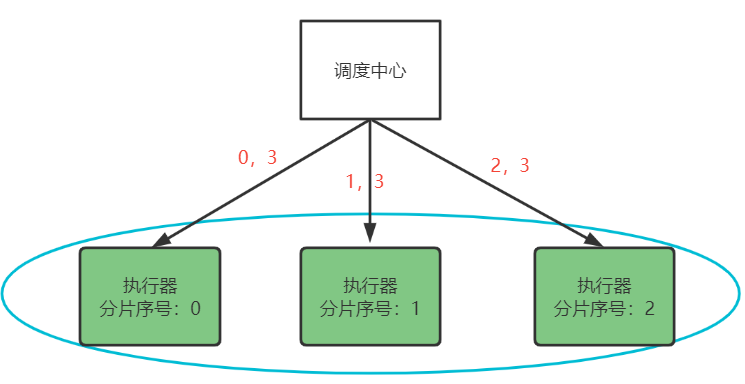

三个实例时，分片参数分别为 `(0,3)、(1,3)、(2,3)`。这些数字表示本轮分工，不是固定机器编号。XXL-JOB 不会自动改写业务查询，Handler 必须按参数筛选自己负责的数据。

下面是不会访问数据库的分片演示：

```java
@XxlJob("shardingJobHandler")
public void shardingJobHandler() {
    int shardIndex = XxlJobHelper.getShardIndex();
    int shardTotal = XxlJobHelper.getShardTotal();
    if (shardTotal <= 0 || shardIndex < 0 || shardIndex >= shardTotal) {
        XxlJobHelper.handleFail("分片参数不合法");
        return;
    }
    XxlJobHelper.log("当前分片 {} / {}", shardIndex, shardTotal);
    long[] ids = {1L, 2L, 3L, 4L, 5L, 6L, 7L, 8L, 9L};
    for (long id : ids) {
        if (id % shardTotal == shardIndex) {
            XxlJobHelper.log("本执行器负责业务记录 {}", id);
        }
    }
}
```

| 参数 | 该演示负责的 ID |
|---|---|
| `shardIndex=0, shardTotal=3` | 3、6、9 |
| `shardIndex=1, shardTotal=3` | 1、4、7 |
| `shardIndex=2, shardTotal=3` | 2、5、8 |

真正的视频任务可以在数据库中使用 `id % shardTotal = shardIndex` 查询当前分片的待处理记录，限制批次大小并原子认领。今天先理解分片参数；状态条件、重试计数、并发抢占和 FFmpeg 执行将在 07 展开。

**分片不保证业务只执行一次**：同一轮稳定参数下它减少不同执行器的查询重叠；重试、扩缩容或旧轮任务仍在运行时，某条记录仍可能被再次选中。应使用数据库条件更新、唯一业务约束或其他幂等控制。机器减少后 `shardTotal` 改变，取模结果也改变，分片编号不能持久化为任务永久归属。


## 29. 双实例分片实验与网络排查

在 Admin 新建 `shardingJobHandler` 任务，运行模式仍为 `BEAN`，把路由策略切到“分片广播”。两个实例使用相同执行器 AppName，使 Admin 把它们放在同一分组。

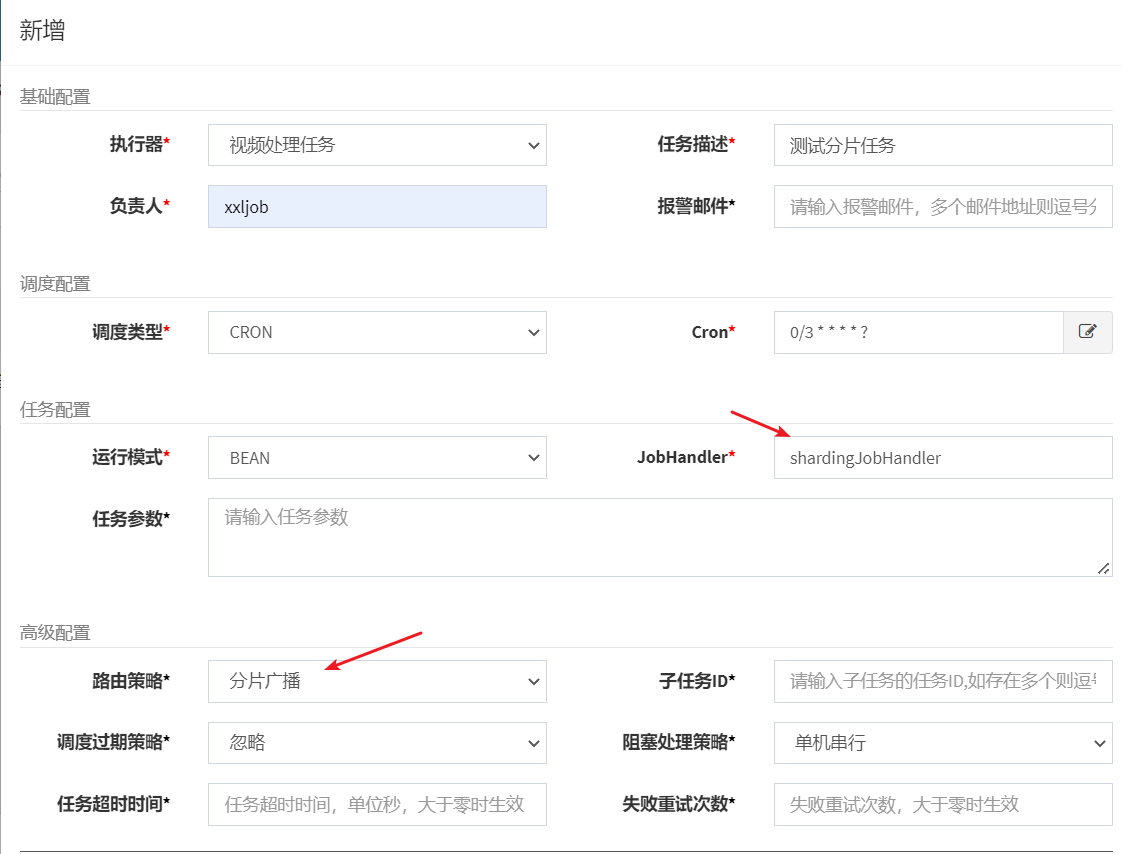

IDEA 复制两份媒资 API 启动配置，设置各自 VM options：

```text
实例 A：-Dserver.port=63050 -Dxxl.job.executor.port=9999
实例 B：-Dserver.port=63051 -Dxxl.job.executor.port=9998
```

两组端口都要区分：API HTTP 端口避免 Tomcat 冲突，执行器端口避免 XXL-JOB 通信冲突。若同机共享任务日志目录造成排查混乱，可以再为两个进程指定各自的日志路径。

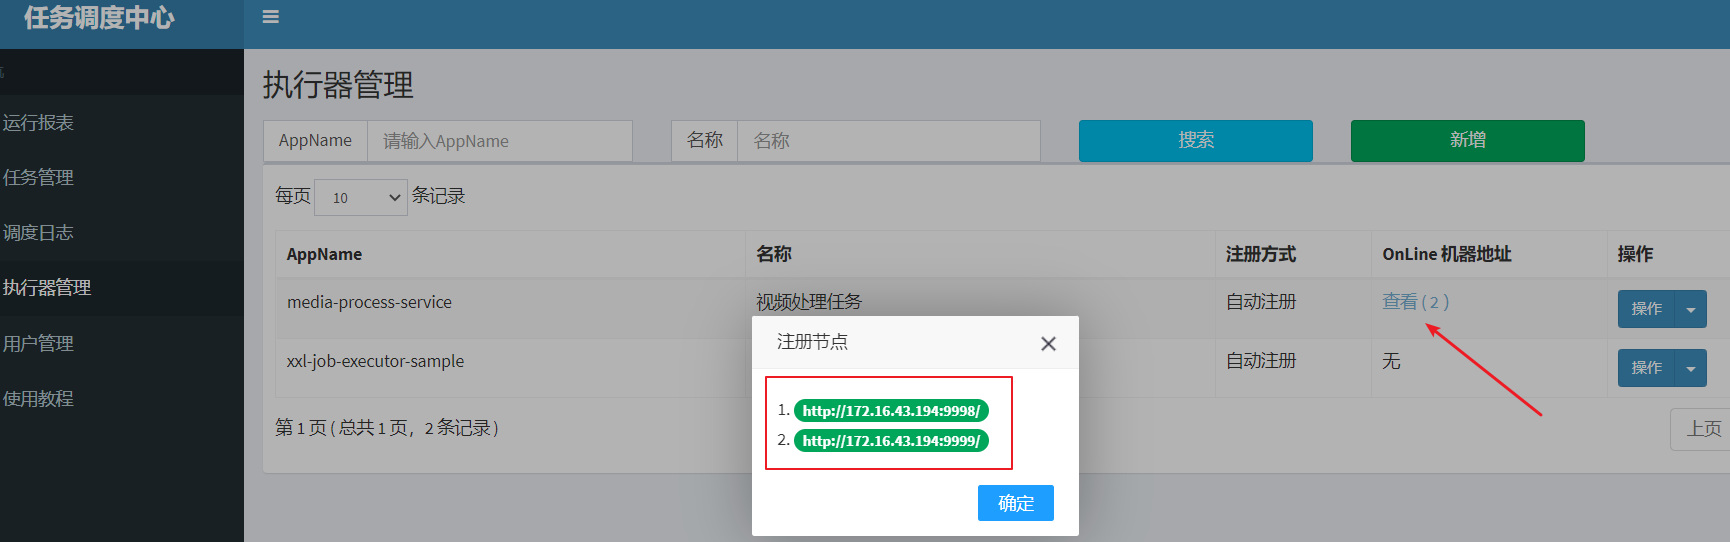

观察 Admin 中有两个在线地址，手动执行一次，两个执行器应分别报告 `0/2` 和 `1/2`。按第 28 节的演示数据，前者处理 2、4、6、8，后者处理 1、3、5、7、9。

再停止一个应用，等待注册信息被调度中心更新后执行，剩余实例应收到 `0/1` 并覆盖全部演示 ID。节点故障后的发现需要时间，不能要求进程停止瞬间分片总数就立刻变化。记录中的任务分工验证应与本轮参数一起观察。

讲义在 Nacos 配置中加入以下项作为本地优先演示：

```yaml
spring:
  cloud:
    config:
      override-none: true
```

**校正**：这是 Spring Cloud Config 相关配置项，不能仅凭这个 key 就断言任意版本的 Nacos 配置都必然让本地参数覆盖远端值。课程环境里要查看启动时最终端口、属性来源与注册地址；真正生效的是当前项目版本的配置优先级。端口不生效时，先核对 VM options 是否填对和远端配置加载情况，再调整实例配置。

| 现象 | 优先排查 |
|---|---|
| 看不到在线执行器 | AppName、Admin URL、Token、Bean 扫描、注册日志 |
| 注册成功但调度失败 | Admin 到执行器 IP / 端口的连通性，容器端口映射 |
| 找不到 JobHandler | 标识不匹配、方法未注册、应用未重启、重复标识 |
| 两个进程启动冲突 | `server.port` 与 `executor.port` 是否都已区分 |
| 只能看到一个地址 | AppName 不同、显式 address 相同、注册了错误 IP |
| 分片仍只有一个实例执行 | 路由策略是否选了分片广播，第二个实例是否在线 |
| Admin 显示成功但业务失败 | Handler 吞掉异常、没有 `handleFail`、异步业务提前返回 |


## 30. 复现清单、章节覆盖与面试提示

本篇串起的两条主线可以分别复述为：**检查整文件 → 检查块 → 补传 → 按序合并 → 校验 → 入库 → 清理**；**配置 Admin → 创建执行器 Bean → 注册 Handler → 配置触发 → 观察日志 → 双实例分片**。

复现时建议依次验收，以下是待在课程环境执行的清单，本次写笔记没有实际启动这些服务：

1. 本地分块与合并：至少 12 块，含非整块尾部；MD5、大小与原文件一致。
2. 分块上传：实际对象 key 与序号匹配；非尾块满足 MinIO 合并大小限制。
3. 续传：上传一部分后刷新，重新选择同一文件，已经存在的块能跳过。
4. 失败行为：缺块、损坏块、参数错误、存储不可达时，不误报成功；临时文件和流被回收。
5. 合并入库：MinIO 有最终对象，媒资记录有正确机构、桶、路径、大小；重复合并结果可解释。
6. 清理：成功上传后的块可回收；放弃上传的块有单独的超时回收方案。
7. 执行器：Admin 显示可访问的地址，手动调用 `testJob` 后能读取执行日志。
8. Cron：正确的秒字段和时区；测试完成停止后续触发。
9. 分片：两个实例参数不同，演示记录分工完整；停掉一个后剩余实例能接管下一轮分工。

| 讲义范围 | 本篇笔记位置 |
|---|---|
| 5.1 需求分析 | 1 |
| 5.2 断点续传、分块合并实验、MinIO 实验 | 2—7 |
| 5.3 接口定义 | 8 |
| 5.4 上传分块开发 | 9—12 |
| 5.5 合并分块开发与测试 | 13—17 |
| 5.6 分块清理问题 | 18—19 |
| 7.2.1 单机与分布式调度 | 20—21 |
| 7.2.2 XXL-JOB 介绍 | 22 |
| 7.2.3 Admin、执行器与任务 | 23—27 |
| 7.2.4 分片广播 | 28—29 |
| 7.1、7.3—7.9 视频处理与并发方案 | 07 继续学习 |

讲义章节编号从第 5 节跳到第 7 节；它是原文件的编号安排，不是漏掉“第 06 天”。笔记继续按网盘 day06 的主题组织。

**面试提示**：

| 问题 | 回答要点 |
|---|---|
| 断点续传如何实现？ | 稳定文件标识与分块参数、服务端记录或查询已存块、只补缺块、最终按序合并并校验 |
| MD5 能直接当权限依据吗？ | 不能；它帮助识别内容，机构归属、使用权限和会话状态需要单独校验 |
| 为什么分块选 5 MiB？ | 课程使用 MinIO multipart 合并，需要满足普通 part 的最小大小，尾 part 可更小 |
| 文件上传成功但入库失败怎么办？ | 两者不在同一个本地事务中，需要幂等、补偿或对账，不能指望数据库回滚撤销 MinIO |
| 为什么自调用事务可能不生效？ | 默认 Spring 代理不会拦截同类内部直接调用，需要经代理或独立 Bean 进入事务方法 |
| XXL-JOB 和普通定时器的区别？ | 集中配置、执行器注册、远程调度、路由、任务日志、重试及分片等管理能力 |
| 什么是分片广播？ | 对各在线执行器发送同一任务并携带序号 / 总数，业务按参数划分数据 |
| 分片是否保证任务不重复？ | 不保证；取模分工之外还要处理重试、扩缩容和跨轮重叠，使用原子认领与幂等 |
| 调度成功是否代表业务成功？ | 不一定；需要 Handler 正确等待业务并上报结果，另核对业务数据与状态 |

下一篇继续 **day07 视频处理、部署门户**：完成待处理视频入库、分片查询与任务认领，结合线程池和 FFmpeg 执行转码，更新业务状态并处理失败重试，再衔接门户环境。
